# Tutorial: estadísticas de jugadores de la NHL con PySpark

En este tutorial se recorre un flujo de trabajo completo, como se haría en un notebook de Databricks:

1. **Cargar** un fichero CSV en un DataFrame de Spark.
2. **Guardarlo en Delta Lake** y aprovechar su historial de versiones.
3. **Revisar la calidad** de los datos y limpiarlos.
4. **Crear variables** con funciones nativas de Spark.
5. **Explorar** los datos con DataFrames y **Spark SQL**.
6. **Visualizar** resultados agregados.
7. **Modelar** con **pipelines de MLlib**: regresión y clasificación con la misma estructura, comparación de modelos, ajuste de hiperparámetros y guardado del modelo.

**Requisitos.** El notebook se ejecuta en el entorno de la asignatura, donde la sesión `spark` (con Delta Lake) y la función `display()` ya existen, igual que en Databricks. El fichero de datos debe estar en `datos/game_skater_stats.csv`, junto al notebook.

## Los datos

El fichero `game_skater_stats.csv` procede del conjunto *NHL Game Data* publicado en Kaggle. Cada fila es la **actuación de un jugador de campo (no portero) en un partido**.

| Columna | Significado |
|---|---|
| `game_id` | Identificador del partido con formato `AAAATTNNNN`: temporada (`AAAA`), tipo de partido (`TT`: 02 = temporada regular, 03 = *playoffs*) y número |
| `player_id`, `team_id` | Identificadores del jugador y de su equipo |
| `timeOnIce` | Tiempo en pista, en segundos |
| `goals`, `assists` | Goles y asistencias |
| `shots` | Tiros a puerta |
| `hits` | Cargas (contacto físico con un rival) |
| `powerPlayGoals`, `powerPlayAssists` | Goles y asistencias en superioridad numérica |
| `shortHandedGoals`, `shortHandedAssists` | Goles y asistencias en inferioridad numérica |
| `penaltyMinutes` | Minutos de penalización |
| `faceOffWins`, `faceoffTaken` | Saques neutrales ganados y disputados |
| `takeaways`, `giveaways` | Recuperaciones y pérdidas de disco |
| `blocked` | Tiros rivales bloqueados |
| `plusMinus` | Diferencia de goles a favor y en contra con el jugador en pista (+/-) |
| `evenTimeOnIce`, `powerPlayTimeOnIce`, `shortHandedTimeOnIce` | Tiempo en pista en igualdad, superioridad e inferioridad (segundos) |

## 0. Configuración

Importaciones, parámetros del tutorial y un estilo común para todas las gráficas. Con el kernel de SageMaker (1 GB de memoria para Spark) los modelos se entrenan automáticamente con el 30 % de los datos; en Docker o en local, con todos. Si el entrenamiento resulta lento, reduzca `FRACCION_MODELOS`.

In [1]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RUTA_CSV = "datos/game_skater_stats.csv"
RUTA_DELTA = "datos/delta/skater_stats"
RUTA_MODELO = "modelos/marca_gol"
SEMILLA = 42

# Fracción de los datos usada para entrenar modelos en la sección 7 (1.0 = todos).
# Con 1 GB de memoria para Spark (el kernel de SageMaker) se usa el 30 % para no
# agotar la memoria de la instancia; puede fijarse a mano si se prefiere.
import os
MEMORIA_SPARK = os.environ.get("SPARK_DRIVER_MEMORY", "2g")
FRACCION_MODELOS = 0.3 if MEMORIA_SPARK.lower() in ("1g", "1024m", "512m") else 1.0

# Estilo común de las gráficas
AZUL, NARANJA, VERDE, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8c8b86"
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titleweight": "bold",
    "lines.linewidth": 2,
})

print(f"Spark {spark.version} · memoria del driver: {MEMORIA_SPARK} · fracción para modelos: {FRACCION_MODELOS}")

Spark 4.2.0 · memoria del driver: 2g · fracción para modelos: 1.0


## 1. Carga de los datos

`spark.read` crea un DataFrame a partir del CSV. Con `header` se toman los nombres de columna de la primera fila y con `inferSchema` Spark deduce el tipo de cada columna (lo que exige leer el fichero una vez más). En Databricks el código es idéntico; solo cambia la ruta (un *volume* o `/FileStore/...`).

Los DataFrames de Spark son **perezosos** (*lazy*): las transformaciones no se ejecutan hasta que una **acción** (`count`, `show`, `display`, `toPandas`, `write`...) necesita el resultado.

In [2]:
df_csv = (spark.read
          .format("csv")
          .option("header", True)
          .option("inferSchema", True)
          .option("sep", ",")
          .load(RUTA_CSV))

df_csv.printSchema()
print(f"Filas: {df_csv.count():,}")
display(df_csv.limit(10))

root
 |-- game_id: integer (nullable = true)
 |-- player_id: integer (nullable = true)
 |-- team_id: integer (nullable = true)
 |-- timeOnIce: integer (nullable = true)
 |-- assists: integer (nullable = true)
 |-- goals: integer (nullable = true)
 |-- shots: integer (nullable = true)
 |-- hits: integer (nullable = true)
 |-- powerPlayGoals: integer (nullable = true)
 |-- powerPlayAssists: integer (nullable = true)
 |-- penaltyMinutes: integer (nullable = true)
 |-- faceOffWins: integer (nullable = true)
 |-- faceoffTaken: integer (nullable = true)
 |-- takeaways: integer (nullable = true)
 |-- giveaways: integer (nullable = true)
 |-- shortHandedGoals: integer (nullable = true)
 |-- shortHandedAssists: integer (nullable = true)
 |-- blocked: integer (nullable = true)
 |-- plusMinus: integer (nullable = true)
 |-- evenTimeOnIce: integer (nullable = true)
 |-- shortHandedTimeOnIce: integer (nullable = true)
 |-- powerPlayTimeOnIce: integer (nullable = true)

Filas: 411,609


,game_id,player_id,team_id,timeOnIce,assists,goals,shots,hits,powerPlayGoals,powerPlayAssists,...,faceoffTaken,takeaways,giveaways,shortHandedGoals,shortHandedAssists,blocked,plusMinus,evenTimeOnIce,shortHandedTimeOnIce,powerPlayTimeOnIce
0,2011030221,8467412,1,999,0,0,1,3,0,0,...,0,0,0,0,0,0,-1,885,98,16
1,2011030221,8468501,1,1168,0,0,0,4,0,0,...,0,1,1,0,0,1,0,767,401,0
2,2011030221,8470609,1,558,0,0,2,1,0,0,...,2,0,0,0,0,1,-1,542,0,16
3,2011030221,8471816,1,1134,0,0,1,4,0,0,...,0,1,0,0,0,1,-1,935,183,16
4,2011030221,8472410,1,436,0,0,1,3,0,0,...,6,0,0,0,0,0,-1,436,0,0
5,2011030221,8471233,1,1344,0,1,4,0,1,0,...,21,0,1,0,0,1,-1,949,239,156
6,2011030221,8470920,1,837,1,0,2,5,0,0,...,2,1,0,0,0,2,1,756,0,81
7,2011030221,8473646,1,465,0,0,2,3,0,0,...,1,0,0,0,0,0,-1,465,0,0
8,2011030221,8470610,1,1327,1,1,3,3,0,1,...,0,1,0,0,0,2,0,903,268,156
9,2011030221,8472382,1,1324,0,0,1,0,0,0,...,0,0,0,0,0,1,-2,1085,220,19


## 2. Almacenamiento en Delta Lake

Delta Lake es el formato de tabla por defecto de Databricks. Sobre ficheros Parquet añade un **registro de transacciones** que permite actualizaciones seguras, consultar el **historial** de cambios y leer versiones anteriores (*time travel*).

- `mode("overwrite")` permite volver a ejecutar la celda: cada ejecución crea una **nueva versión** de la tabla en lugar de fallar porque la carpeta ya existe.
- Para leer una tabla Delta hay que indicar siempre `format("delta")`.

In [3]:
df_csv.write.format("delta").mode("overwrite").save(RUTA_DELTA)

df = spark.read.format("delta").load(RUTA_DELTA)
print(f"Filas en la tabla Delta: {df.count():,}")

Filas en la tabla Delta: 411,609


## 3. Calidad de los datos

Antes de analizar conviene comprobar dos cosas: si hay **valores nulos** y si hay **filas duplicadas**. Ambas comprobaciones se escriben con funciones nativas de Spark y se calculan en paralelo sobre todo el conjunto.

In [4]:
# Número de nulos por columna (una sola pasada sobre los datos)
nulos = df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns])
display(nulos)

,game_id,player_id,team_id,timeOnIce,assists,goals,shots,hits,powerPlayGoals,powerPlayAssists,...,faceoffTaken,takeaways,giveaways,shortHandedGoals,shortHandedAssists,blocked,plusMinus,evenTimeOnIce,shortHandedTimeOnIce,powerPlayTimeOnIce
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
# Cada combinación (partido, jugador) debería aparecer una sola vez
total = df.count()
distintas = df.dropDuplicates(["game_id", "player_id"]).count()
print(f"Filas: {total:,} · combinaciones (partido, jugador) distintas: {distintas:,} · duplicadas: {total - distintas:,}")

Filas: 411,609 · combinaciones (partido, jugador) distintas: 411,578 · duplicadas: 31


Eliminamos los duplicados y **sobrescribimos la tabla Delta**. La versión anterior no se pierde: queda en el historial y se puede seguir leyendo.

In [6]:
(df.dropDuplicates(["game_id", "player_id"])
   .write.format("delta").mode("overwrite").save(RUTA_DELTA))

In [7]:
from delta.tables import DeltaTable

tabla = DeltaTable.forPath(spark, RUTA_DELTA)
historial = tabla.history().select("version", "timestamp", "operation",
                                   F.col("operationMetrics")["numOutputRows"].alias("filas_escritas"))
display(historial)

# Time travel: leer la versión anterior a la actual
version_actual = historial.agg(F.max("version")).first()[0]
anterior = spark.read.format("delta").option("versionAsOf", version_actual - 1).load(RUTA_DELTA)
actual = spark.read.format("delta").load(RUTA_DELTA)
print(f"Versión {version_actual - 1}: {anterior.count():,} filas  ->  versión {version_actual}: {actual.count():,} filas")

,version,timestamp,operation,filas_escritas
0,1,2026-10-07 17:42:31.334,WRITE,411578
1,0,2026-10-07 17:42:17.883,WRITE,411609


Versión 0: 411,609 filas  ->  versión 1: 411,578 filas


## 4. Variables derivadas

Las nuevas columnas se crean con las **funciones nativas** de `pyspark.sql.functions` (`F.substring`, `F.when`, `F.round`...). Spark las optimiza y las ejecuta dentro de la JVM.

Variables que añadimos:

- `temporada` y `tipo_partido`, extraídas de `game_id`.
- `minutos` en pista (más legible que los segundos).
- `puntos` = goles + asistencias, la medida habitual de producción ofensiva.
- `marca`: 1 si el jugador marcó al menos un gol en el partido, 0 si no (la usaremos para clasificación).

`cache()` mantiene el resultado en memoria, porque lo vamos a reutilizar muchas veces.

In [8]:
id_texto = F.col("game_id").cast("string")

df = (spark.read.format("delta").load(RUTA_DELTA)
      .withColumn("temporada", F.substring(id_texto, 1, 4).cast("int"))
      .withColumn("tipo_partido",
                  F.when(F.substring(id_texto, 5, 2) == "02", "Temporada regular")
                   .when(F.substring(id_texto, 5, 2) == "03", "Playoffs")
                   .otherwise("Otros"))
      .withColumn("minutos", F.round(F.col("timeOnIce") / 60, 2))
      .withColumn("puntos", F.col("goals") + F.col("assists"))
      .withColumn("marca", (F.col("goals") > 0).cast("int"))
      .cache())

display(df.select("game_id", "temporada", "tipo_partido", "minutos",
                  "goals", "assists", "puntos", "marca").limit(10))

,game_id,temporada,tipo_partido,minutos,goals,assists,puntos,marca
0,2018020973,2018,Temporada regular,19.97,1,0,1,1
1,2018020973,2018,Temporada regular,10.87,0,1,1,0
2,2018020973,2018,Temporada regular,17.25,0,0,0,0
3,2018020973,2018,Temporada regular,15.77,0,0,0,0
4,2018020973,2018,Temporada regular,27.05,0,1,1,0
5,2018020974,2018,Temporada regular,16.00,0,0,0,0
6,2018020974,2018,Temporada regular,12.92,1,0,1,1
7,2018020974,2018,Temporada regular,15.32,0,0,0,0
8,2018020974,2018,Temporada regular,16.72,0,0,0,0
9,2018020974,2018,Temporada regular,10.15,0,0,0,0


In [9]:
# Resumen estadístico de las variables principales
display(df.select("minutos", "goals", "assists", "shots", "hits", "plusMinus")
          .summary("mean", "stddev", "min", "25%", "50%", "75%", "max"))

,summary,minutos,goals,assists,shots,hits,plusMinus
0,mean,16.560248847120103,0.15239881626325993,0.25857067190180233,1.688545063147204,1.3115764205083849,-0.007529556973404798
1,stddev,4.964624990423407,0.40448980367230586,0.5272846688677891,1.5417464863737456,1.4612363909472108,1.1030918344201013
2,min,0.02,0,0,0,0,-7
3,25%,13.3,0,0,1,0,-1
4,50%,16.68,0,0,1,1,0
5,75%,19.87,0,0,3,2,1
6,max,53.28,5,5,15,15,6


## 5. Exploración con Spark SQL

Registrando el DataFrame como **vista temporal** se puede consultar con SQL, igual que con una celda `%sql` de Databricks. El resultado de `spark.sql` es otro DataFrame.

> Los identificadores de jugador se pueden traducir a nombres uniendo (`join`) esta tabla con `player_info.csv`, del mismo conjunto de datos. Se propone como ejercicio al final.

In [10]:
df.createOrReplaceTempView("stats")

top_goleadores = spark.sql('''
    SELECT player_id,
           COUNT(*)                          AS partidos,
           SUM(goals)                        AS goles,
           SUM(assists)                      AS asistencias,
           ROUND(SUM(goals) / COUNT(*), 3)   AS goles_por_partido,
           ROUND(SUM(goals) / SUM(shots), 3) AS acierto
    FROM stats
    GROUP BY player_id
    HAVING COUNT(*) >= 100
    ORDER BY goles DESC
    LIMIT 10
''')
display(top_goleadores)

,player_id,partidos,goles,asistencias,goles_por_partido,acierto
0,8471214,788,434,334,0.551,0.125
1,8474564,655,342,336,0.522,0.169
2,8474141,748,311,478,0.416,0.123
3,8475166,700,308,374,0.440,0.133
4,8470794,782,305,350,0.390,0.132
5,8471675,674,299,515,0.444,0.142
6,8473419,769,292,349,0.380,0.153
7,8473548,776,285,419,0.367,0.111
8,8471215,643,282,434,0.439,0.134
9,8474053,739,279,316,0.378,0.128


La misma consulta puede escribirse con la API de DataFrames. Ambas formas generan el **mismo plan de ejecución**, así que se puede elegir la que resulte más clara en cada caso. Aquí calculamos los partidos y el tiempo medio en pista por temporada y tipo de partido:

In [11]:
resumen_temporadas = (df.groupBy("temporada", "tipo_partido")
                        .agg(F.count("*").alias("actuaciones"),
                             F.round(F.avg("minutos"), 2).alias("minutos_medios"),
                             F.round(F.sum("goals") / F.sum("shots"), 3).alias("acierto"))
                        .orderBy("temporada", "tipo_partido"))
display(resumen_temporadas)

,temporada,tipo_partido,actuaciones,minutos_medios,acierto
0,2010,Playoffs,3204,17.11,0.087
1,2010,Temporada regular,44262,16.51,0.090
2,2011,Playoffs,3096,17.12,0.082
3,2011,Temporada regular,44275,16.54,0.089
4,2012,Playoffs,3096,17.37,0.079
5,2012,Temporada regular,25918,16.52,0.091
6,2013,Playoffs,3348,17.19,0.092
7,2013,Temporada regular,44275,16.54,0.089
8,2014,Playoffs,3204,17.15,0.083
9,2014,Temporada regular,44274,16.57,0.089


## 6. Visualización

Patrón que se repite en todas las gráficas: **agregar en Spark** (sobre todos los datos, en paralelo) y pasar a pandas con `toPandas()` **solo el resultado**, que tiene pocas filas. Pasar a pandas el DataFrame completo no escalaría y puede agotar la memoria.

### 6.1 ¿Cuántos goles marca un jugador en un partido?

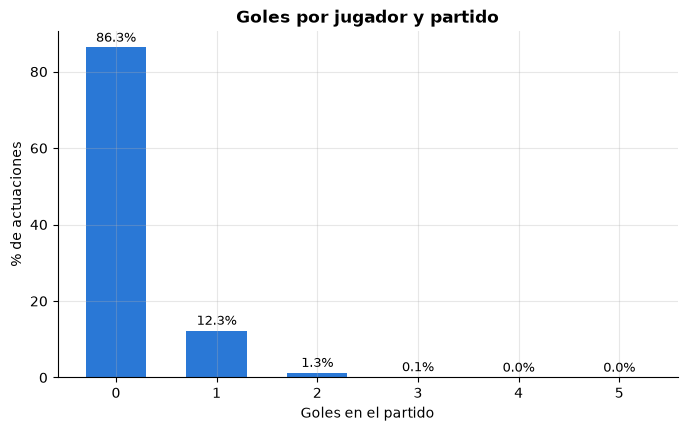

In [12]:
dist = df.groupBy("goals").count().orderBy("goals").toPandas()
dist["porcentaje"] = 100 * dist["count"] / dist["count"].sum()

fig, ax = plt.subplots()
barras = ax.bar(dist["goals"].astype(str), dist["porcentaje"], color=AZUL, width=0.6)
ax.bar_label(barras, fmt="%.1f%%", padding=2, fontsize=9)
ax.set(title="Goles por jugador y partido", xlabel="Goles en el partido", ylabel="% de actuaciones")
plt.show()

La gran mayoría de las actuaciones terminan sin gol: marcar es un suceso **raro**. Lo tendremos en cuenta al interpretar los modelos de la sección 7.

### 6.2 Probabilidad de marcar según el número de tiros

`F.least` agrupa en una sola categoría los partidos con 10 tiros o más, y la media de `marca` en cada grupo es la proporción de actuaciones con gol.

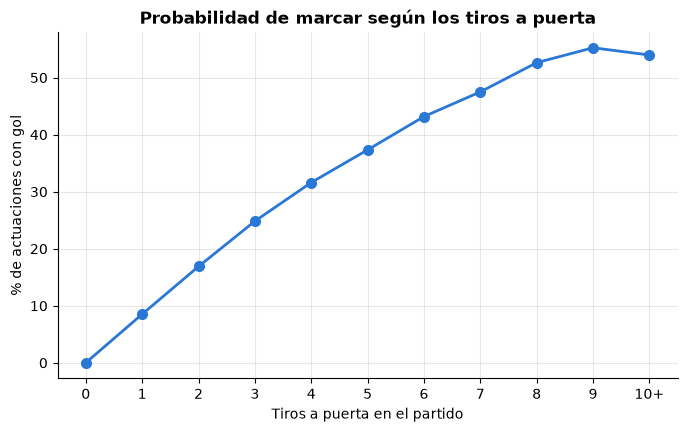

In [13]:
prob = (df.withColumn("tiros", F.least(F.col("shots"), F.lit(10)))
          .groupBy("tiros")
          .agg(F.avg("marca").alias("prob_marcar"), F.count("*").alias("actuaciones"))
          .orderBy("tiros")
          .toPandas())

fig, ax = plt.subplots()
ax.plot(prob["tiros"], 100 * prob["prob_marcar"], color=AZUL, marker="o", markersize=7)
ax.set_xticks(prob["tiros"], [str(t) if t < 10 else "10+" for t in prob["tiros"]])
ax.set(title="Probabilidad de marcar según los tiros a puerta",
       xlabel="Tiros a puerta en el partido", ylabel="% de actuaciones con gol")
plt.show()

### 6.3 Evolución del acierto por temporada

`pivot` convierte los valores de una columna (`tipo_partido`) en columnas, lo que deja los datos listos para dibujar una línea por tipo de partido.

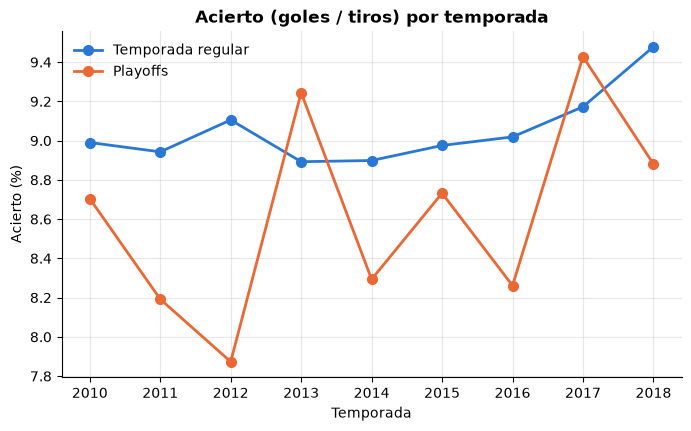

In [14]:
acierto = (df.filter(F.col("tipo_partido") != "Otros")
             .groupBy("temporada")
             .pivot("tipo_partido", ["Temporada regular", "Playoffs"])
             .agg(F.sum("goals") / F.sum("shots"))
             .orderBy("temporada")
             .toPandas())

fig, ax = plt.subplots()
for serie, color in [("Temporada regular", AZUL), ("Playoffs", NARANJA)]:
    ax.plot(acierto["temporada"], 100 * acierto[serie], color=color, marker="o", markersize=7, label=serie)
ax.set(title="Acierto (goles / tiros) por temporada", xlabel="Temporada", ylabel="Acierto (%)")
ax.set_xticks(acierto["temporada"])
ax.legend(frameon=False)
plt.show()

### 6.4 Correlación entre variables

`pyspark.ml.stat.Correlation` calcula la matriz de correlaciones sobre todos los datos de forma distribuida. Necesita que las variables estén reunidas en un único vector, que es justo lo que hace `VectorAssembler` (lo volveremos a usar en los pipelines).

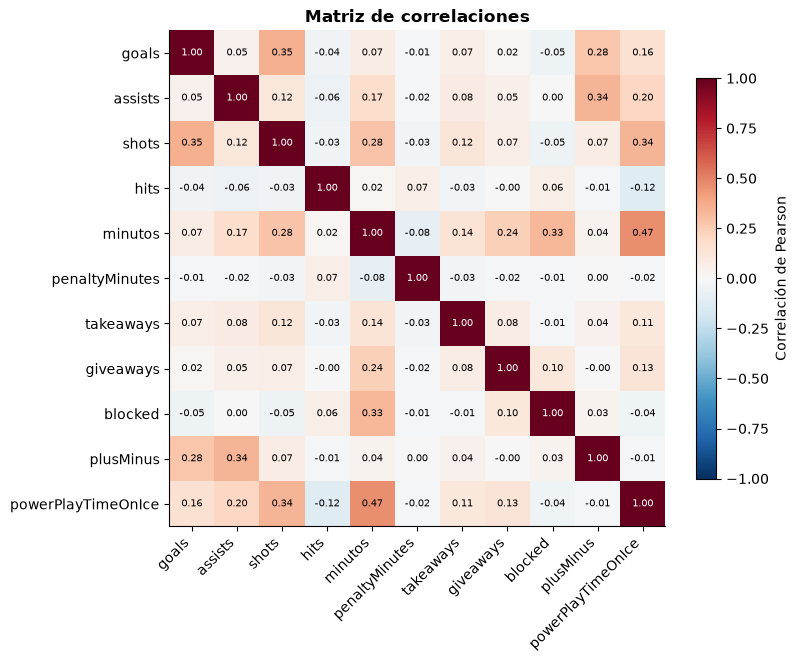

In [15]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation

variables_corr = ["goals", "assists", "shots", "hits", "minutos", "penaltyMinutes",
                  "takeaways", "giveaways", "blocked", "plusMinus", "powerPlayTimeOnIce"]
vectores = VectorAssembler(inputCols=variables_corr, outputCol="v").transform(df).select("v")
matriz = Correlation.corr(vectores, "v", "pearson").first()[0].toArray()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(matriz, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(variables_corr)), variables_corr, rotation=45, ha="right")
ax.set_yticks(range(len(variables_corr)), variables_corr)
ax.grid(False)
for i in range(len(variables_corr)):
    for j in range(len(variables_corr)):
        ax.text(j, i, f"{matriz[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(matriz[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8, label="Correlación de Pearson")
ax.set_title("Matriz de correlaciones")
plt.show()

### 6.5 Un jugador a lo largo del tiempo: funciones de ventana

Las **funciones de ventana** calculan valores que dependen de las filas vecinas sin agrupar los datos. Aquí calculamos la **media móvil de puntos en los últimos 10 partidos** de un jugador. Como `game_id` empieza por la temporada, ordenar por él equivale a ordenar cronológicamente.

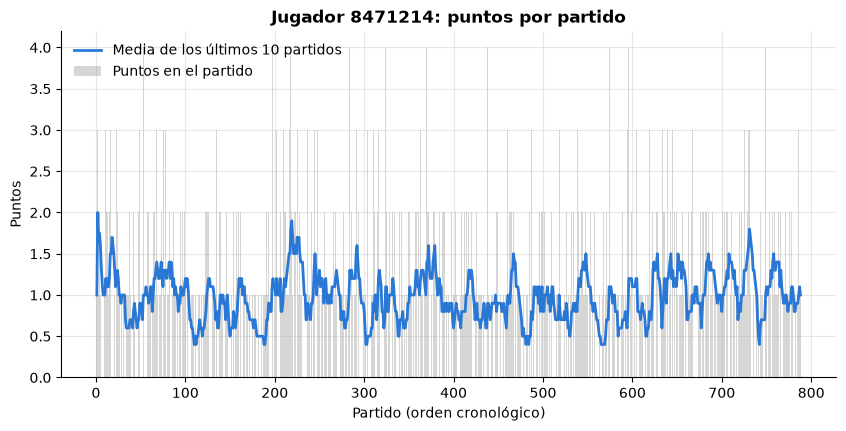

In [16]:
JUGADOR = 8471214
if df.filter(F.col("player_id") == JUGADOR).limit(1).count() == 0:
    JUGADOR = top_goleadores.first()["player_id"]   # si no está, el máximo goleador

ventana = Window.partitionBy("player_id").orderBy("game_id").rowsBetween(-9, 0)

jugador = (df.filter(F.col("player_id") == JUGADOR)
             .withColumn("partido", F.row_number().over(Window.partitionBy("player_id").orderBy("game_id")))
             .withColumn("puntos_media10", F.avg("puntos").over(ventana))
             .select("partido", "temporada", "minutos", "shots", "goals", "puntos", "puntos_media10")
             .orderBy("partido")
             .toPandas())

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(jugador["partido"], jugador["puntos"], color=GRIS, alpha=0.35, width=1.0, label="Puntos en el partido")
ax.plot(jugador["partido"], jugador["puntos_media10"], color=AZUL, label="Media de los últimos 10 partidos")
ax.set(title=f"Jugador {JUGADOR}: puntos por partido", xlabel="Partido (orden cronológico)", ylabel="Puntos")
ax.legend(frameon=False)
plt.show()

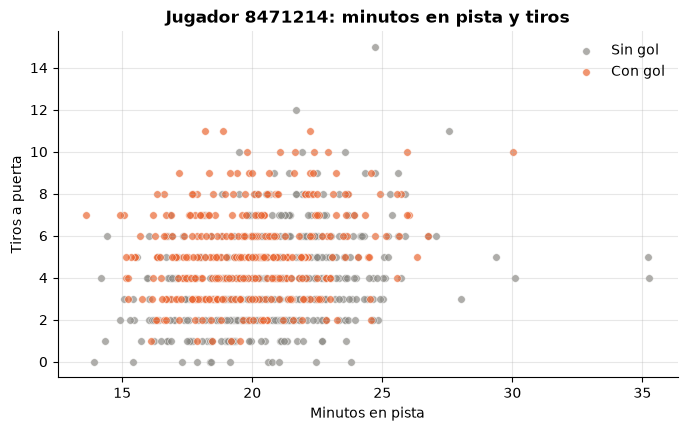

In [17]:
# Relación entre minutos jugados y tiros para el mismo jugador
fig, ax = plt.subplots()
for con_gol, color, etiqueta in [(False, GRIS, "Sin gol"), (True, NARANJA, "Con gol")]:
    sub = jugador[(jugador["goals"] > 0) == con_gol]
    ax.scatter(sub["minutos"], sub["shots"], s=30, color=color, alpha=0.7,
               edgecolors="white", linewidths=0.5, label=etiqueta)
ax.set(title=f"Jugador {JUGADOR}: minutos en pista y tiros", xlabel="Minutos en pista", ylabel="Tiros a puerta")
ax.legend(frameon=False)
plt.show()

## 7. Modelado con pipelines de MLlib

Un **`Pipeline`** encadena todas las etapas de preparación y el modelo en un único objeto. Ventajas:

- La **misma preparación** se aplica exactamente igual al entrenar y al predecir.
- Se pueden **comparar modelos** cambiando solo la última etapa.
- El pipeline entrenado (`PipelineModel`) se **guarda y carga** como una unidad.

Todos los modelos de esta sección comparten la misma preparación:

1. `StringIndexer` + `OneHotEncoder`: convierten la variable categórica `tipo_partido` en variables numéricas.
2. `VectorAssembler`: reúne todas las variables en un vector.
3. `StandardScaler`: tipifica las variables (media 0, desviación 1). Es útil para los modelos lineales y no afecta a los árboles.

In [18]:
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import StringIndexer, OneHotEncoder, StandardScaler

VARIABLES = ["shots", "hits", "assists", "minutos", "penaltyMinutes", "takeaways",
             "giveaways", "blocked", "powerPlayTimeOnIce", "shortHandedTimeOnIce"]

def preparacion():
    # Etapas comunes a todos los modelos (se crean nuevas en cada llamada)
    return [
        StringIndexer(inputCol="tipo_partido", outputCol="tipo_idx", handleInvalid="keep"),
        OneHotEncoder(inputCols=["tipo_idx"], outputCols=["tipo_ohe"]),
        VectorAssembler(inputCols=VARIABLES + ["tipo_ohe"], outputCol="variables"),
        StandardScaler(inputCol="variables", outputCol="features", withMean=True, withStd=True),
    ]

def crear_pipeline(modelo):
    return Pipeline(stages=preparacion() + [modelo])

def nombres_variables(df_transformado):
    # Nombres de las posiciones del vector 'variables' (a partir de sus metadatos)
    attrs = df_transformado.schema["variables"].metadata["ml_attr"]["attrs"]
    return [a["name"] for a in sorted((a for grupo in attrs.values() for a in grupo), key=lambda a: a["idx"])]

**Entrenamiento y prueba.** Separamos los datos **una sola vez, antes de entrenar nada**, y evaluamos siempre sobre el conjunto de prueba. Evaluar con los mismos datos usados para entrenar daría una idea demasiado optimista del modelo.

Para ahorrar memoria, se guardan en caché solo las columnas que necesitan los modelos y se libera la caché del DataFrame completo (`unpersist`). Es una práctica recomendable siempre que se trabaja con recursos limitados.

In [19]:
# Solo las columnas que usan los modelos: ocupan mucha menos memoria en caché
datos_modelo = df.select(VARIABLES + ["tipo_partido", "goals", "marca"])
if FRACCION_MODELOS < 1:
    datos_modelo = datos_modelo.sample(fraction=FRACCION_MODELOS, seed=SEMILLA)

train, test = datos_modelo.randomSplit([0.8, 0.2], seed=SEMILLA)
train.cache(); test.cache()
print(f"Entrenamiento: {train.count():,} filas · prueba: {test.count():,} filas")

# El DataFrame completo ya no hace falta en memoria: se libera para los modelos
df.unpersist()

Entrenamiento: 329,594 filas · prueba: 81,984 filas


DataFrame[game_id: int, player_id: int, team_id: int, timeOnIce: int, assists: int, goals: int, shots: int, hits: int, powerPlayGoals: int, powerPlayAssists: int, penaltyMinutes: int, faceOffWins: int, faceoffTaken: int, takeaways: int, giveaways: int, shortHandedGoals: int, shortHandedAssists: int, blocked: int, plusMinus: int, evenTimeOnIce: int, shortHandedTimeOnIce: int, powerPlayTimeOnIce: int, temporada: int, tipo_partido: string, minutos: double, puntos: int, marca: int]

### 7.1 Regresión: ¿cuántos goles marca un jugador?

Comparamos tres modelos con la misma función de evaluación. Como referencia incluimos el modelo más simple posible: predecir siempre la media de goles del conjunto de entrenamiento. Un modelo útil debe mejorar claramente su error.

In [20]:
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

def evaluar_regresion(nombre, modelo):
    ajustado = crear_pipeline(modelo).fit(train)
    pred = ajustado.transform(test)
    metricas = {m: RegressionEvaluator(labelCol="goals", metricName=m).evaluate(pred)
                for m in ["rmse", "mae", "r2"]}
    return ajustado, pred, {"modelo": nombre, **metricas}

modelos_reg = {
    "Regresión lineal": LinearRegression(labelCol="goals"),
    "Random forest": RandomForestRegressor(labelCol="goals", numTrees=30, maxDepth=6, seed=SEMILLA),
    "Gradient boosting": GBTRegressor(labelCol="goals", maxIter=20, maxDepth=4, seed=SEMILLA),
}

# Modelo de referencia: predecir siempre la media de entrenamiento
media = train.agg(F.avg("goals")).first()[0]
ref = test.withColumn("prediction", F.lit(media))
resultados_reg = [{"modelo": "Referencia (media)",
                   **{m: RegressionEvaluator(labelCol="goals", metricName=m).evaluate(ref)
                      for m in ["rmse", "mae", "r2"]}}]

ajustados_reg = {}
for nombre, modelo in modelos_reg.items():
    ajustados_reg[nombre], pred, fila = evaluar_regresion(nombre, modelo)
    resultados_reg.append(fila)

tabla_reg = pd.DataFrame(resultados_reg).set_index("modelo").round(4)
display(tabla_reg)

,rmse,mae,r2
modelo,,,
Referencia (media),0.4056,0.2639,-0.0000
Regresión lineal,0.3792,0.2360,0.1261
Random forest,0.3797,0.2354,0.1238
Gradient boosting,0.3773,0.2283,0.1350


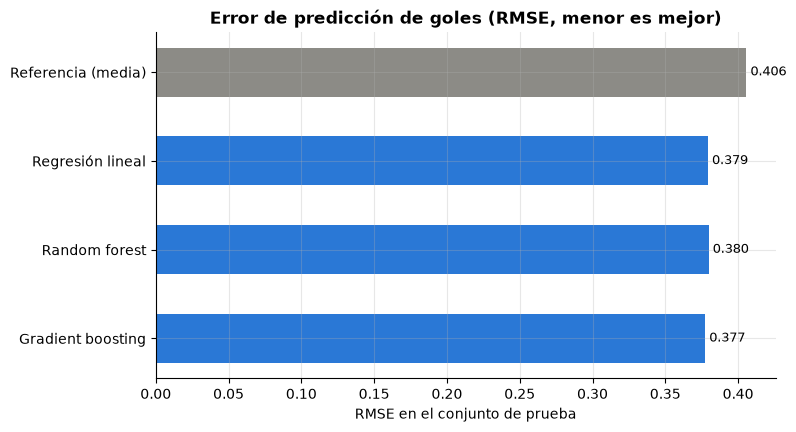

In [21]:
fig, ax = plt.subplots()
barras = ax.barh(tabla_reg.index, tabla_reg["rmse"], color=[GRIS] + [AZUL] * 3, height=0.55)
ax.bar_label(barras, fmt="%.3f", padding=3, fontsize=9)
ax.invert_yaxis()
ax.set(title="Error de predicción de goles (RMSE, menor es mejor)", xlabel="RMSE en el conjunto de prueba")
plt.show()

**¿Qué variables usa el modelo?** Los modelos de árboles indican la **importancia** de cada variable, y la regresión lineal sus **coeficientes**. Como las variables están tipificadas, los coeficientes son comparables entre sí: indican cuántos goles más (o menos) se esperan al aumentar la variable en una desviación típica.

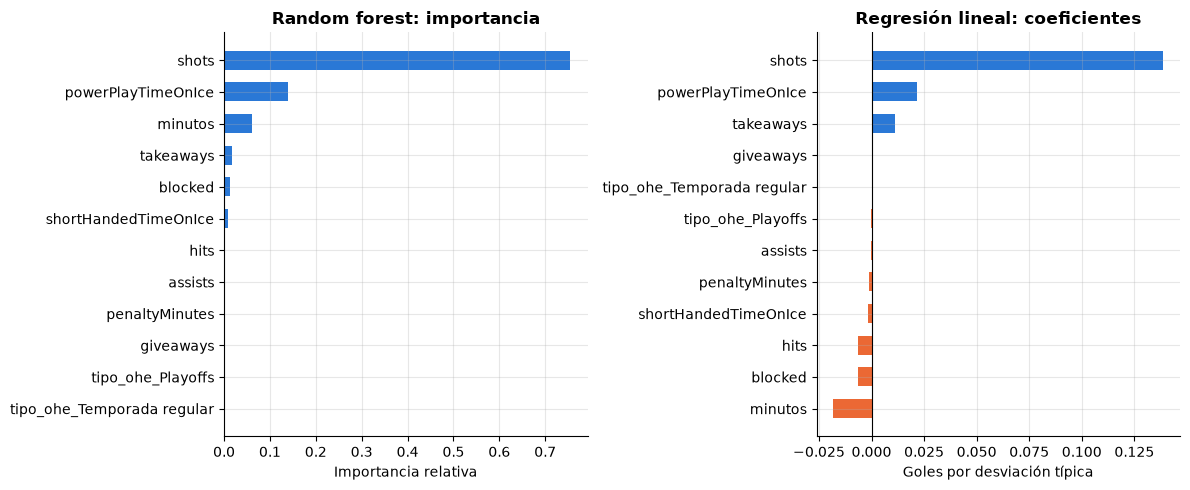

In [22]:
nombres = nombres_variables(ajustados_reg["Random forest"].transform(test.limit(1)))

importancias = pd.Series(ajustados_reg["Random forest"].stages[-1].featureImportances.toArray(),
                         index=nombres).sort_values()
coeficientes = pd.Series(ajustados_reg["Regresión lineal"].stages[-1].coefficients.toArray(),
                         index=nombres).sort_values()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.barh(importancias.index, importancias.values, color=AZUL, height=0.6)
ax1.set(title="Random forest: importancia", xlabel="Importancia relativa")
ax2.barh(coeficientes.index, coeficientes.values, height=0.6,
         color=[AZUL if v >= 0 else NARANJA for v in coeficientes.values])
ax2.axvline(0, color="black", linewidth=0.8)
ax2.set(title="Regresión lineal: coeficientes", xlabel="Goles por desviación típica")
plt.tight_layout()
plt.show()

### 7.2 Clasificación: ¿marcará el jugador al menos un gol?

Como los goles son raros, a menudo tiene más sentido predecir **si** el jugador marcará. Reutilizamos exactamente la misma preparación; solo cambian el modelo, la etiqueta (`marca`) y las métricas.

- **AUC**: probabilidad de que el modelo puntúe más alto una actuación con gol que una sin gol (0,5 = azar, 1 = perfecto).
- **Exactitud** (*accuracy*): proporción de aciertos. Con clases desequilibradas engaña: predecir siempre «sin gol» ya acierta mucho, por eso la mostramos junto a esa referencia.

In [23]:
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

def evaluar_clasificacion(nombre, modelo):
    ajustado = crear_pipeline(modelo).fit(train)
    pred = ajustado.transform(test)
    fila = {"modelo": nombre,
            "auc": BinaryClassificationEvaluator(labelCol="marca", metricName="areaUnderROC").evaluate(pred),
            "exactitud": MulticlassClassificationEvaluator(labelCol="marca", metricName="accuracy").evaluate(pred),
            "f1": MulticlassClassificationEvaluator(labelCol="marca", metricName="f1").evaluate(pred)}
    return ajustado, fila

modelos_clf = {
    "Regresión logística": LogisticRegression(labelCol="marca"),
    "Random forest": RandomForestClassifier(labelCol="marca", numTrees=30, maxDepth=6, seed=SEMILLA),
    "Gradient boosting": GBTClassifier(labelCol="marca", maxIter=20, maxDepth=4, seed=SEMILLA),
}

ajustados_clf, resultados_clf = {}, []
for nombre, modelo in modelos_clf.items():
    ajustados_clf[nombre], fila = evaluar_clasificacion(nombre, modelo)
    resultados_clf.append(fila)

tabla_clf = pd.DataFrame(resultados_clf).set_index("modelo").round(4)
sin_gol = 1 - test.agg(F.avg("marca")).first()[0]
print(f"Referencia: predecir siempre «sin gol» tiene una exactitud de {sin_gol:.4f}")
display(tabla_clf)

Referencia: predecir siempre «sin gol» tiene una exactitud de 0.8615


,auc,exactitud,f1
modelo,,,
Regresión logística,0.7749,0.8594,0.8157
Random forest,0.7597,0.8615,0.7973
Gradient boosting,0.7807,0.8617,0.8058


**Curva ROC.** Muestra, para cada umbral de decisión, la proporción de goles detectados frente a la de falsas alarmas. Los modelos de regresión logística y *random forest* calculan la curva directamente con `evaluate()`, aplicado a los datos de prueba ya preparados por las etapas comunes del pipeline.

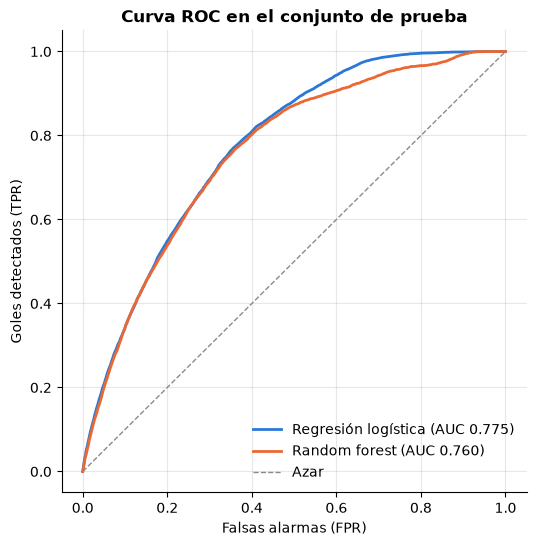

In [24]:
fig, ax = plt.subplots(figsize=(6, 6))
for nombre, color in [("Regresión logística", AZUL), ("Random forest", NARANJA)]:
    ajustado = ajustados_clf[nombre]
    preparados = PipelineModel(stages=ajustado.stages[:-1]).transform(test)
    roc = ajustado.stages[-1].evaluate(preparados).roc.toPandas()
    ax.plot(roc["FPR"], roc["TPR"], color=color, label=f"{nombre} (AUC {tabla_clf.loc[nombre, 'auc']:.3f})")
ax.plot([0, 1], [0, 1], color=GRIS, linestyle="--", linewidth=1, label="Azar")
ax.set(title="Curva ROC en el conjunto de prueba", xlabel="Falsas alarmas (FPR)", ylabel="Goles detectados (TPR)")
ax.legend(frameon=False, loc="lower right")
plt.show()

### 7.3 Ajuste de hiperparámetros con validación cruzada

`CrossValidator` prueba todas las combinaciones de una rejilla de hiperparámetros (`ParamGridBuilder`) mediante validación cruzada sobre el conjunto de entrenamiento, y se queda con la mejor. Recibe **el pipeline completo**, así que la preparación también se repite correctamente en cada partición.

In [25]:
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

logistica = LogisticRegression(labelCol="marca")
rejilla = (ParamGridBuilder()
           .addGrid(logistica.regParam, [0.0, 0.01, 0.1])
           .addGrid(logistica.elasticNetParam, [0.0, 0.5])
           .build())

cv = CrossValidator(estimator=crear_pipeline(logistica),
                    estimatorParamMaps=rejilla,
                    evaluator=BinaryClassificationEvaluator(labelCol="marca"),
                    numFolds=3, parallelism=1, seed=SEMILLA)
cv_modelo = cv.fit(train)

resultados_cv = pd.DataFrame([{"regParam": p[logistica.regParam], "elasticNetParam": p[logistica.elasticNetParam],
                               "auc_medio": m} for p, m in zip(rejilla, cv_modelo.avgMetrics)])
display(resultados_cv.sort_values("auc_medio", ascending=False).round(4))

mejor = cv_modelo.bestModel
auc_test = BinaryClassificationEvaluator(labelCol="marca").evaluate(mejor.transform(test))
print(f"AUC del mejor modelo en el conjunto de prueba: {auc_test:.4f}")

,regParam,elasticNetParam,auc_medio
3,0.01,0.5,0.7797
0,0.00,0.0,0.7792
1,0.00,0.5,0.7792
2,0.01,0.0,0.7790
4,0.10,0.0,0.7747
5,0.10,0.5,0.7705


AUC del mejor modelo en el conjunto de prueba: 0.7755


### 7.4 Guardar el modelo y usarlo con datos nuevos

El `PipelineModel` incluye la preparación y el modelo, así que para predecir basta con un DataFrame que tenga **las mismas columnas de entrada**. Es la forma habitual de poner un modelo en producción en Databricks.

In [26]:
mejor.write().overwrite().save(RUTA_MODELO)
modelo_cargado = PipelineModel.load(RUTA_MODELO)

nuevas = spark.createDataFrame(
    [("Temporada regular", 1, 1, 0, 12.0, 0, 0, 1, 1, 0, 0),
     ("Playoffs",          6, 3, 1, 21.5, 2, 1, 0, 0, 240, 0)],
    ["tipo_partido"] + VARIABLES)

from pyspark.ml.functions import vector_to_array
display(modelo_cargado.transform(nuevas)
        .withColumn("prob_marcar", F.round(vector_to_array("probability")[1], 3))
        .select("tipo_partido", "shots", "minutos", "powerPlayTimeOnIce", "prob_marcar", "prediction"))

,tipo_partido,shots,minutos,powerPlayTimeOnIce,prob_marcar,prediction
0,Temporada regular,1,12.0,0,0.076,0.0
1,Playoffs,6,21.5,240,0.561,1.0
